# Benchmark analysis: the references

Reads the binary benchmark's CSVs (`benchmark_sft.py sweep`) and describes them; nothing here runs the mechanism. The outcome is the outcome tests' and H3's divergence D = |m₀ − m₁| / 2 (`metrics.divergence`), m_c community c's mean pole, read from the final opinions. `classify()`'s regimes are shown beside it (§ 3).

| Artifact | Committed run | Read as |
|---|---|---|
| `logs/benchmark/canon_binary_20k.csv`, `canon_binary_20k_divergence.csv` | ε = 0.1, 20,000 rounds, p_inter = 0–0.50, seeds 1–300 | the canon scan, at the canon's own horizon, D̄(p_inter, H), and the check that the benchmark has not moved |
| `logs/benchmark/symmetric_binary_20k.csv`, `symmetric_binary_20k_divergence.csv` | ε = 0.1 on both sides, both learning, 20,000 rounds, p_inter = 0–0.50, seeds 1–300 | the symmetric benchmark, D̄(p_inter, t) at every round, read at H and 20,000 (§ 2) |
| `logs/benchmark/assimilation_binary_20k.csv`, `assimilation_symmetric_binary_20k.csv`, each with its `_divergence.csv` | the canon scan and the symmetric benchmark with `--rule assimilation`, same seeds and horizon | the assimilation benchmarks, D̄(p_inter, t) beside their SFT pairs (§ 5) |
| `logs/benchmark/canon_binary_100.csv`, `symmetric_binary_100.csv`, each with its `_divergence.csv` | the same two at H = 100 rounds, same seeds | each run's state and labels at H, the regimes at H (§ 3); their D̄ curve is the first H rounds of the `_20k` pair's (`../schedule.md` § References), asserted in § 3 |

The sweeps that wrote them (`../schedule.md` § References), from the repo root:

```bash
python analysis/benchmark/benchmark_sft.py sweep --epsilon 0.1 --reps 300 --max-rounds 20000 \
  --jobs 6 --out analysis/logs/benchmark/canon_binary_20k.csv
python analysis/benchmark/benchmark_sft.py sweep --both-learn --epsilon 0.1 --reps 300 --max-rounds 20000 \
  --jobs 6 --out analysis/logs/benchmark/symmetric_binary_20k.csv
python analysis/benchmark/benchmark_sft.py sweep --epsilon 0.1 --reps 300 --max-rounds 100 \
  --jobs 6 --out analysis/logs/benchmark/canon_binary_100.csv
python analysis/benchmark/benchmark_sft.py sweep --both-learn --epsilon 0.1 --reps 300 --max-rounds 100 \
  --jobs 6 --out analysis/logs/benchmark/symmetric_binary_100.csv
python analysis/benchmark/benchmark_sft.py sweep --rule assimilation --epsilon 0.1 --reps 300 --max-rounds 20000 \
  --jobs 6 --out analysis/logs/benchmark/assimilation_binary_20k.csv
python analysis/benchmark/benchmark_sft.py sweep --rule assimilation --both-learn --epsilon 0.1 --reps 300 --max-rounds 20000 \
  --jobs 6 --out analysis/logs/benchmark/assimilation_symmetric_binary_20k.csv
```

`EXPECT` (§ 1) holds the canon scan's settings. Each sidecar records the commit and command that wrote its CSV.

Every sweep numbers seeds 1..reps, so a seed draws the same graph in each. The canon scan's rows hold only its last round, so the read at H is D̄ in `canon_binary_20k_divergence.csv` (§ 2); the regimes at H come from the `_100` rows (§ 3).

The notebook counts p_inter in grid steps, 100 p_inter (one expected cross edge each), so the grid is the integers 0–50 and indexes arrays directly; `SBM_P_INTER` is a step / 100.

## 1. Load and provenance

In [8]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)  # every table at three decimals

CWD = Path.cwd().resolve()
REPO = next(p for p in [CWD, *CWD.parents] if (p / "simulation" / "config.py").is_file())
sys.path.insert(0, str(REPO / "analysis" / "benchmark"))
from benchmark_sft import CONVICTION, NETWORK_MAX_ROUNDS, SBM_PAIRS_INTER  # noqa: E402
import metrics  # noqa: E402
import recovery  # noqa: E402   (benchmark_sft put analysis/ on the path)

LOGS = REPO / "analysis" / "logs" / "benchmark"
# Named, never globbed: nothing written beside these can pool in.
CANON = LOGS / "canon_binary_20k.csv"
CANON_CURVE = LOGS / "canon_binary_20k_divergence.csv"         # § 2
SYMMETRIC_CURVE = LOGS / "symmetric_binary_20k_divergence.csv"   # § 2
SYMMETRIC = LOGS / "symmetric_binary_20k.csv"                     # § 3
CANON_H, SYMMETRIC_H = LOGS / "canon_binary_100.csv", LOGS / "symmetric_binary_100.csv"   # § 3
ASSIM_CURVE = LOGS / "assimilation_binary_20k_divergence.csv"                 # § 5
ASSIM_SYM_CURVE = LOGS / "assimilation_symmetric_binary_20k_divergence.csv"   # § 5
# The canon scan's settings (cell 0).
EXPECT = {"reps": 300, "max_rounds": 20_000, "epsilon": 0.1}
H = NETWORK_MAX_ROUNDS
STEP = SBM_PAIRS_INTER            # grid steps per unit p_inter: one expected cross edge each
GRID = list(range(0, STEP // 2 + 1))
ER = STEP // 2                     # p_inter = 0.5
LABEL = f"canon scan at 20,000 rounds, {EXPECT['reps']:,} seeds"

def read_rows(path: Path) -> tuple[pd.DataFrame, dict]:
    """A sweep's rows, p_inter in grid steps, and its sidecar."""
    d = pd.read_csv(path)
    d["p100"] = (d["p_inter"] * STEP).round().astype(int)
    assert np.allclose(d["p100"] / STEP, d["p_inter"]), "p_inter off the grid"
    return d, json.loads(path.with_suffix(path.suffix + ".params.json").read_text(encoding="utf-8"))


canon, meta = read_rows(CANON)
r = meta["resolved"]
print(f"canon_binary_20k {len(canon):>6} rows  commit {meta['commit'][:8]}  "
      f"epsilon={r['epsilon']}  rounds={r['max_rounds']}  reps={r['reps']}  "
      f"N={meta['config']['NUM_AGENTS']}")

canon_binary_20k  15300 rows  commit fab22471  epsilon=0.1  rounds=20000  reps=300  N=20


In [9]:
# The set-up, asserted rather than trusted.
assert r["epsilon"] == EXPECT["epsilon"] and not r.get("both_learn")
assert meta["config"]["NUM_AGENTS"] == 20 and meta["conviction"] == CONVICTION
assert r["max_rounds"] == EXPECT["max_rounds"] and (canon["rounds"] == EXPECT["max_rounds"]).all()
per_p = canon.groupby("p100")["seed"].agg(["count", "nunique", "min", "max"])
assert list(per_p.index) == GRID
assert (per_p["count"] == EXPECT["reps"]).all() and (per_p["nunique"] == EXPECT["reps"]).all()
assert (per_p["min"] == 1).all() and (per_p["max"] == EXPECT["reps"]).all()
print("ok: agent i alone learning, N = 20; every p_inter in 0-0.50 with seeds 1..reps at the full horizon")


ok: agent i alone learning, N = 20; every p_inter in 0-0.50 with seeds 1..reps at the full horizon


## 2. D̄(p_inter): the mean divergence per coupling

The canon scan's and the symmetric benchmark's mean D at H and at 20,000 rounds, each from its `_divergence.csv` (the canon's 20,000 also from its rows), with normal 95 % intervals. One panel per R, recovery's 33 and its nested 17 and 9 (`recovery.grid`, `recovery.STEPS`); its verticals mark the p_inter the runs measure at.

In [10]:
def mean_table(t: pd.DataFrame) -> pd.DataFrame:
    """Add the normal 95% interval of the mean D per row, from its sd and n."""
    t = t.copy()
    half = metrics.Z95 * t["sd"] / np.sqrt(t["n"])
    t["lo"], t["hi"] = t["mean"] - half, t["mean"] + half
    return t


def divergence_at(t: int, c: pd.DataFrame) -> pd.DataFrame:
    """Mean D per p_inter at round t, from a sweep's per-round moments."""
    return mean_table(c.loc[c["round"] == t, ["p100", "mean", "sd", "n"]].reset_index(drop=True))


def read_curve(path: Path) -> pd.DataFrame:
    c = pd.read_csv(path).rename(columns={"n_runs": "n"})
    c["p100"] = (c["p_inter"] * STEP).round().astype(int)
    return c


curve = read_curve(CANON_CURVE)
sym_curve = read_curve(SYMMETRIC_CURVE)
sym = json.loads(SYMMETRIC_CURVE.with_suffix(SYMMETRIC_CURVE.suffix + ".params.json").read_text(encoding="utf-8"))["resolved"]
assert sym["both_learn"] and sym["epsilon"] == EXPECT["epsilon"] and sym["reps"] == EXPECT["reps"]
assert sym["max_rounds"] == EXPECT["max_rounds"] and (sym_curve["n"] == EXPECT["reps"]).all()
by_p = canon.groupby("p100")["divergence"]
d_20000 = mean_table(by_p.agg(mean="mean", sd="std", n="count").reset_index())
assert np.allclose(d_20000[["mean", "sd"]], divergence_at(EXPECT["max_rounds"], curve)[["mean", "sd"]],
                   atol=1e-5)   # rows and curve agree
d_H = divergence_at(H, curve)
sym_20000, sym_H = divergence_at(EXPECT["max_rounds"], sym_curve), divergence_at(H, sym_curve)
pd.set_option("display.max_rows", 60)
pd.DataFrame({"canon_20000": d_20000.set_index("p100")["mean"], f"canon_{H}": d_H.set_index("p100")["mean"],
              "symmetric_20000": sym_20000.set_index("p100")["mean"], f"symmetric_{H}": sym_H.set_index("p100")["mean"]})


,canon_20000,canon_100,symmetric_20000,symmetric_100
p100,,,,
0,1.000,1.000e+00,0.933,9.333e-01
1,0.997,9.967e-01,0.930,9.300e-01
2,0.973,9.733e-01,0.893,8.933e-01
3,0.957,9.567e-01,0.863,8.633e-01
4,0.950,9.500e-01,0.847,8.467e-01
5,0.917,9.167e-01,0.810,8.100e-01
6,0.920,9.200e-01,0.790,7.900e-01
7,0.887,8.867e-01,0.787,7.867e-01
8,0.870,8.700e-01,0.740,7.400e-01


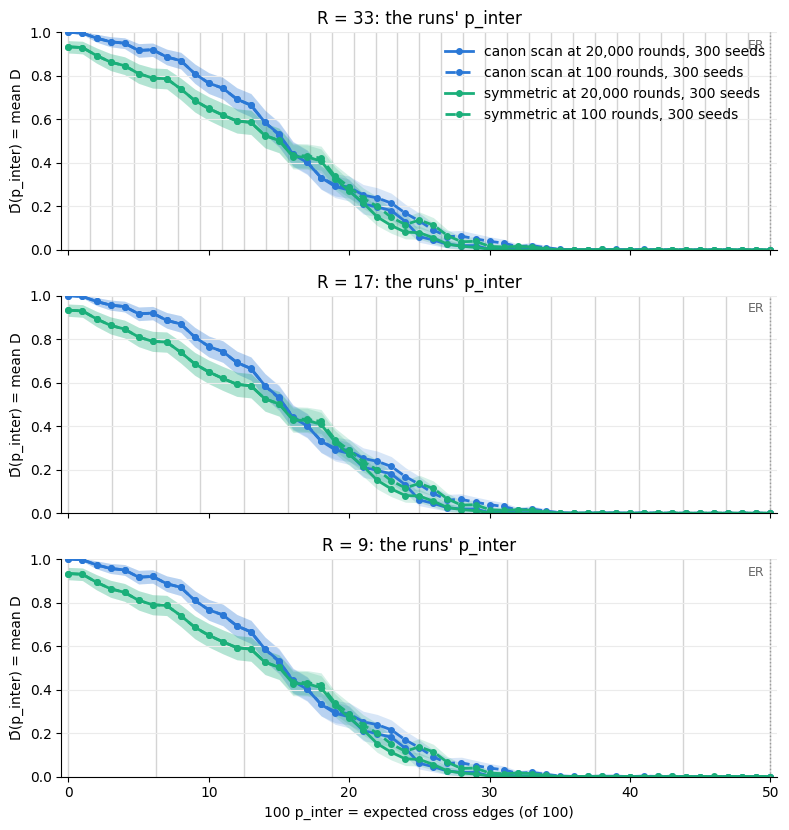

In [16]:
# Panel = R; colour = benchmark (blue canon scan, green symmetric), line = horizon (solid 20,000,
# dashed H); verticals = the p_inter the panel's runs measure at.
R_RUNS = 33   # recovery's R (recovery.ipynb), read also at every 2nd and 4th run (recovery.STEPS)
RS = sorted(((R_RUNS - 1) // step + 1 for step in recovery.STEPS), reverse=True)
seeds = f"{EXPECT['reps']:,} seeds"
fig, axes = plt.subplots(len(RS), 1, figsize=(8, 8.4), sharex=True, sharey=True)
for ax, R in zip(axes, RS):
    for x in recovery.grid(R) * STEP:
        ax.axvline(x, color="0.45", lw=1, alpha=0.3, zorder=0)
    for t, color, ls, label in ((d_20000, "#2a78d6", "-", LABEL),
                                (d_H, "#2a78d6", "--", f"canon scan at {H} rounds, {seeds}"),
                                (sym_20000, "#1baf7a", "-", f"symmetric at 20,000 rounds, {seeds}"),
                                (sym_H, "#1baf7a", "--", f"symmetric at {H} rounds, {seeds}")):
        ax.fill_between(t["p100"], t["lo"], t["hi"], color=color, alpha=0.18, lw=0)
        ax.plot(t["p100"], t["mean"], color=color, lw=2, ls=ls, marker="o", ms=4, label=label)
    ax.axvline(ER, color="0.6", lw=1, ls=":")
    ax.text(ER - 0.4, 0.97, "ER", ha="right", va="top", color="0.4", fontsize=9)
    ax.set(title=f"R = {R}: the runs' p_inter", ylabel="D̄(p_inter) = mean D", xlim=(-0.5, ER + 0.5), ylim=(0, 1))
    ax.grid(axis="y", color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("100 p_inter = expected cross edges (of 100)")
axes[0].legend(frameon=False, loc="center right")
plt.tight_layout()


## 3. Regime composition

All four labels of `benchmark_sft.classify()` per p_inter, for the canon scan and the symmetric benchmark (rows) at H and at 20,000 rounds (columns). Under the binary reward the (+) and (−) consensus shares should be equal up to sampling; `unsettled` is a block mean below the conviction threshold at the run's last round.

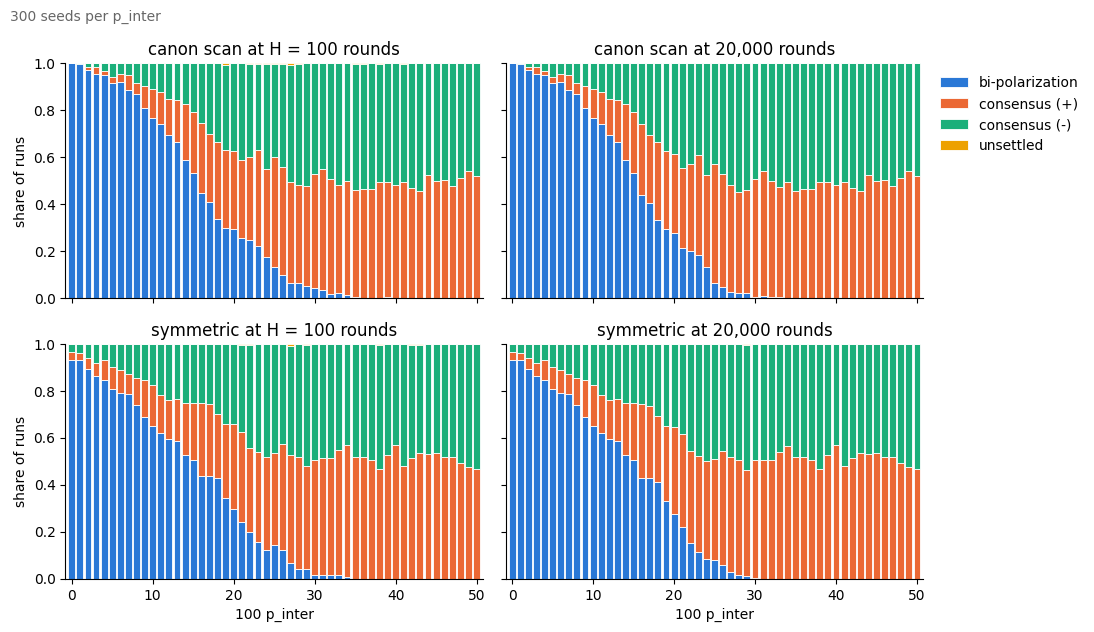

In [27]:
REGIMES = ["bi-polarization", "consensus (+)", "consensus (-)", "unsettled"]
REGIME_COLOR = dict(zip(REGIMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))


def checked(path: Path, both_learn: bool, rounds: int, c: pd.DataFrame) -> pd.DataFrame:
    """A sweep's rows, its settings asserted; its mean D at H must be its _20k curve's at H."""
    d, m = read_rows(path)
    rs = m["resolved"]
    assert bool(rs.get("both_learn")) == both_learn and rs["epsilon"] == EXPECT["epsilon"]
    assert rs["reps"] == EXPECT["reps"] and rs["max_rounds"] == rounds and (d["rounds"] == rounds).all()
    assert m["config"]["NUM_AGENTS"] == 20 and m["conviction"] == CONVICTION
    assert (d.groupby("p100")["seed"].agg(lambda s: sorted(s) == list(range(1, EXPECT["reps"] + 1)))).all()
    assert list(d["p100"].drop_duplicates().sort_values()) == GRID
    if rounds == H:
        assert np.allclose(d.groupby("p100")["divergence"].mean(), divergence_at(H, c)["mean"], atol=1e-5)
    unknown = set(d["regime"]) - set(REGIMES)
    assert not unknown, unknown
    return d


panels = {("canon scan", H): checked(CANON_H, False, H, curve),
          ("canon scan", EXPECT["max_rounds"]): canon,
          ("symmetric", H): checked(SYMMETRIC_H, True, H, sym_curve),
          ("symmetric", EXPECT["max_rounds"]): checked(SYMMETRIC, True, EXPECT["max_rounds"], sym_curve)}

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, ((bench, t), d) in zip(axes.flat, panels.items()):
    comp = (pd.crosstab(d["p100"], d["regime"], normalize="index")
              .reindex(index=GRID, columns=REGIMES, fill_value=0.0))
    bottom = np.zeros(len(GRID))
    for reg in REGIMES:
        v = comp[reg].to_numpy()
        ax.bar(GRID, v, bottom=bottom, width=0.85, color=REGIME_COLOR[reg], label=reg,
               edgecolor="white", linewidth=0.6)
        bottom += v
    ax.set(title=f"{bench} at {'H = ' if t == H else ''}{t:,} rounds", xlim=(-0.8, ER + 0.8))
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("100 p_inter")
for ax in axes[:, 0]:
    ax.set_ylabel("share of runs")
axes[0, 1].legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle(f"{EXPECT['reps']:,} seeds per p_inter", x=0.01, ha="left", fontsize=10, color="0.4")
plt.tight_layout()

In [28]:
# Direction symmetry: consensus (+) among consensus runs, pooled over p_inter. A seed's runs
# share its random stream and nested graph at every p_inter, so they are not independent: the
# 95% interval clusters by seed (ratio estimator, delta-method SE over seeds).
cons = canon[canon["regime"].str.startswith("consensus")]
by_seed = cons.groupby("seed")["regime"].agg(k=lambda r: r.eq("consensus (+)").sum(), n="size")
k, n, s = by_seed["k"].sum(), by_seed["n"].sum(), len(by_seed)
p = k / n
se = np.sqrt(s / (s - 1) * ((by_seed["k"] - p * by_seed["n"]) ** 2).sum()) / n
print(f"P(+ | consensus) = {p:.3f}  [{p - 1.96 * se:.3f}, {p + 1.96 * se:.3f}]  {n} runs, {s} seeds")


P(+ | consensus) = 0.491  [0.461, 0.521]  10517 runs, 300 seeds


## 4. Settling of D̄

A p_inter's settle round is the last round t at which D̄(p_inter, t) lies outside the normal 95 % interval of D̄(p_inter, 20,000), 0 if it never does. It is read off each benchmark's `_divergence.csv` (§ 2), so it describes the mean over the seeds, not single runs. A settle round above H means D̄ at H is not yet within sampling error of its 20,000-round value, the gap between § 2's two curves. Where every run's D is 0 at 20,000 the interval has width 0, and the settle round is the last round any run's D was above 0. At ε > 0 no state is absorbing (Meylahn & Meylahn 2024), so a late settle round is a recurrence, not a delay.

canon scan                          symmetric                         
         settle      D_100  D_end   half    settle      D_100  D_end   half
p100                                                                       
0             0  1.000e+00  1.000  0.000         5  9.333e-01  0.933  0.028
1             5  9.967e-01  0.997  0.007         5  9.300e-01  0.930  0.029
2             5  9.733e-01  0.973  0.018         4  8.933e-01  0.893  0.035
3             6  9.567e-01  0.957  0.023         4  8.633e-01  0.863  0.039
4             7  9.500e-01  0.950  0.025         4  8.467e-01  0.847  0.041
5             6  9.167e-01  0.917  0.031         4  8.100e-01  0.810  0.044
6             6  9.200e-01  0.920  0.031         5  7.900e-01  0.790  0.046
7             7  8.867e-01  0.887  0.036         5  7.867e-01  0.787  0.046
8             7  8.700e-01  0.870  0.038         4  7.400e-01  0.740  0.050
9             5  8.100e-01  0.810  0.044         3  6.863e-01  0.687  0.053
10            5  7.667e-01  0.766  0.048         3  6.490e-01  0.650  0.054
11            5  7.427e-01  0.743  0.050         3  6.197e-01  0.619  0.055
12            1  6.930e-01  0.693  0.052         3  5.923e-01  0.593  0.056
13            1  6.643e-01  0.666  0.053         4  5.857e-01  0.586  0.056
14            1  5.860e-01  0.586  0.056         3  5.260e-01  0.525  0.056
15            2  5.280e-01  0.532  0.056         2  5.033e-01  0.503  0.057
16            2  4.427e-01  0.439  0.056         0  4.340e-01  0.428  0.056
17           10  4.047e-01  0.402  0.055         0  4.317e-01  0.427  0.056
18           12  3.320e-01  0.332  0.053         0  4.217e-01  0.408  0.055
19           17  2.987e-01  0.291  0.051         9  3.383e-01  0.327  0.053
20           25  2.887e-01  0.275  0.050        13  2.890e-01  0.270  0.050
21           66  2.520e-01  0.211  0.046        20  2.370e-01  0.216  0.046
22           77  2.387e-01  0.197  0.045       616  2.000e-01  0.151  0.040
23           34  2.150e-01  0.181  0.043       533  1.497e-01  0.112  0.035
24          147  1.687e-01  0.130  0.038       133  1.163e-01  0.081  0.031
25         6048  1.327e-01  0.061  0.027      1161  1.370e-01  0.079  0.030
26         2331  9.100e-02  0.045  0.023      2402  1.137e-01  0.055  0.026
27         2377  6.133e-02  0.025  0.017       938  6.567e-02  0.026  0.018
28         1040  6.333e-02  0.019  0.015      1161  3.733e-02  0.017  0.015
29          886  5.067e-02  0.020  0.016      4485  3.933e-02  0.011  0.011
30         6560  3.933e-02  0.003  0.006      2358  1.600e-02  0.003  0.006
31          500  3.100e-02  0.009  0.011      4820  1.333e-02  0.000  0.000
32          183  1.500e-02  0.003  0.006     16366  1.600e-02  0.000  0.000
33         1027  1.967e-02  0.003  0.006      6885  1.400e-02  0.000  0.000
34         1634  1.033e-02  0.000  0.000       412  5.667e-03  0.000  0.000
35          211  3.000e-03  0.000  0.000        90  0.000e+00  0.000  0.000
36          211  6.670e-04  0.000  0.000        89  0.000e+00  0.000  0.000
37          140  1.000e-03  0.000  0.000       127  6.670e-04  0.000  0.000
38          133  1.667e-03  0.000  0.000       119  1.667e-03  0.000  0.000
39          185  2.000e-03  0.000  0.000       107  0.000e+00  0.000  0.000
40           96  0.000e+00  0.000  0.000        65  0.000e+00  0.000  0.000
41          133  2.333e-03  0.000  0.000        56  0.000e+00  0.000  0.000
42          141  6.670e-04  0.000  0.000       121  1.333e-03  0.000  0.000
43          141  6.670e-04  0.000  0.000       121  1.333e-03  0.000  0.000
44           78  0.000e+00  0.000  0.000        80  0.000e+00  0.000  0.000
45           75  0.000e+00  0.000  0.000        68  0.000e+00  0.000  0.000
46           80  0.000e+00  0.000  0.000       105  1.000e-03  0.000  0.000
47          100  3.330e-04  0.000  0.000        45  0.000e+00  0.000  0.000
48          150  3.330e-04  0.000  0.000        69  0.000e+00  0.000  0.000
49          150  3.330e-04  0.000  0.000        80  0

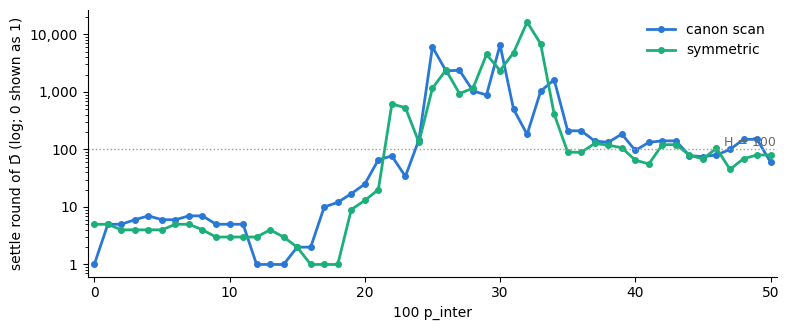

In [29]:
def settle_of(c: pd.DataFrame) -> pd.DataFrame:
    """Per p_inter: the last round D̄ lies outside the 95% interval of D̄ at the sweep's end."""
    rows = []
    for p100, g in c.groupby("p100"):
        g = g.set_index("round")
        end = g.loc[EXPECT["max_rounds"]]
        half = metrics.Z95 * end["sd"] / np.sqrt(end["n"])
        out = g.index[(g["mean"] - end["mean"]).abs() > half]
        rows.append({"p100": p100, "settle": int(out.max()) if len(out) else 0,
                     f"D_{H}": g.loc[H, "mean"], "D_end": end["mean"], "half": half})
    return pd.DataFrame(rows).set_index("p100")


settle = {"canon scan": settle_of(curve), "symmetric": settle_of(sym_curve)}

fig, ax = plt.subplots(figsize=(8, 3.4))
for (bench, s), color in zip(settle.items(), ("#2a78d6", "#1baf7a")):
    ax.plot(s.index, s["settle"].clip(lower=1), color=color, lw=2, marker="o", ms=4, label=bench)
ax.axhline(H, color="0.6", lw=1, ls=":")
ax.text(-0.4, H, f"H = {H}", ha="left", va="bottom", color="0.4", fontsize=9)
ax.set(yscale="log", xlabel="100 p_inter", ylabel="settle round of D̄ (log; 0 shown as 1)", xlim=(-0.5, ER + 0.5))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,g}"))   # decimal labels on log axes, not 10^n
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
pd.concat(settle, axis=1)

## 5. Assimilation against SFT

The assimilation benchmarks (`--rule assimilation`, [`../README.md`](../README.md#the-references) § The references) beside their SFT pairs: one-sided against the canon scan, symmetric against the symmetric benchmark. Each learner traces its partners' argued poles, A ← A + α(s_partner − A), and declares sign(A); everything else is the pair's, and one seed draws the same graph, pairings and exploration under both rules, so a pair's gap is the update's. Where the curves meet, D alone cannot tell feedback from influence at that p_inter. First D̄(p_inter) at H and 20,000, then D̄(t) at six couplings.

In [ ]:
def assimilation_curve(path: Path, both_learn: bool) -> pd.DataFrame:
    """An assimilation sweep's D per round, its settings asserted against the SFT pair's."""
    c = read_curve(path)
    m = json.loads(path.with_suffix(path.suffix + ".params.json").read_text(encoding="utf-8"))["resolved"]
    assert m["rule"] == "assimilation" and bool(m["both_learn"]) == both_learn and m["start"] == "polarized"
    assert m["epsilon"] == EXPECT["epsilon"] and m["reps"] == EXPECT["reps"] and m["max_rounds"] == EXPECT["max_rounds"]
    assert (c["n"] == EXPECT["reps"]).all() and sorted(c["p100"].unique()) == GRID
    return c


# side -> (SFT curve, assimilation curve)
pairs = {"one-sided": (curve, assimilation_curve(ASSIM_CURVE, False)),
         "symmetric": (sym_curve, assimilation_curve(ASSIM_SYM_CURVE, True))}
pd.DataFrame({f"{side} {rule} {t}": divergence_at(t, c).set_index("p100")["mean"]
              for side, cs in pairs.items() for rule, c in zip(("SFT", "assim"), cs)
              for t in (H, EXPECT["max_rounds"])})

In [ ]:
# Panel = side; colour = rule (blue SFT, orange assimilation), line = horizon (solid 20,000, dashed H).
RULE_COLOR = {"SFT": "#2a78d6", "assimilation": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (side, cs) in zip(axes, pairs.items()):
    for rule, c in zip(RULE_COLOR, cs):
        for t, ls in ((EXPECT["max_rounds"], "-"), (H, "--")):
            d = divergence_at(t, c)
            ax.fill_between(d["p100"], d["lo"], d["hi"], color=RULE_COLOR[rule], alpha=0.18, lw=0)
            ax.plot(d["p100"], d["mean"], color=RULE_COLOR[rule], lw=2, ls=ls, marker="o", ms=3,
                    label=f"{rule} at {'H = ' if t == H else ''}{t:,}")
    ax.axvline(ER, color="0.6", lw=1, ls=":")
    ax.set(title=side, xlabel="100 p_inter", xlim=(-0.5, ER + 0.5), ylim=(0, 1))
    ax.grid(axis="y", color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("D̄(p_inter) = mean D")
axes[1].legend(frameon=False)
fig.suptitle(f"{EXPECT['reps']:,} seeds per p_inter", x=0.01, ha="left", fontsize=10, color="0.4")
plt.tight_layout()

In [ ]:
# D̄(t) per coupling: colour = rule, line = side (solid symmetric, dashed one-sided); 95% bands.
SHOWN = (5, 10, 15, 20, 25, 35)   # 100 p_inter: from the canon's high plateau through its fall to 0
SIDE_LS = {"one-sided": "--", "symmetric": "-"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for ax, p100 in zip(axes.flat, SHOWN):
    for side, cs in pairs.items():
        for rule, c in zip(RULE_COLOR, cs):
            g = c[c["p100"] == p100]
            half = metrics.Z95 * g["sd"] / np.sqrt(g["n"])
            ax.fill_between(g["round"], g["mean"] - half, g["mean"] + half, color=RULE_COLOR[rule], alpha=0.15, lw=0)
            ax.plot(g["round"], g["mean"], color=RULE_COLOR[rule], ls=SIDE_LS[side], lw=1.6, label=f"{rule}, {side}")
    ax.axvline(H, color="0.6", lw=1, ls=":")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,g}"))   # decimal labels on log axes, not 10^n
    ax.set(title=f"p_inter = {p100 / STEP:.2f}", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("round t (log; dotted: H)")
for ax in axes[:, 0]:
    ax.set_ylabel("D̄(t)")
axes[0, 2].legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()